**Listing Directory Contents**

In [3]:
import os

# The '.' represents the current directory where your notebook is saved.
# If you placed the dataset folder somewhere else, replace '.' with the path to that folder.
dataset_path = './Dataset_BUSI_with_GT' 
contents = os.listdir(dataset_path)

print(contents)




['benign', 'malignant', 'normal']


In [4]:
# Counting Images in Each Class

classes = ['benign', 'malignant', 'normal']

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    num_files = len(os.listdir(class_path))
    print(f'Number of {class_name} images: {num_files}')

Number of benign images: 891
Number of malignant images: 421
Number of normal images: 266


[[[  7   7   7]
  [  2   2   2]
  [  4   4   4]
  ...
  [197 197 197]
  [184 184 184]
  [176 176 176]]

 [[198 198 198]
  [ 45  45  45]
  [  0   0   0]
  ...
  [200 200 200]
  [191 191 191]
  [183 183 183]]

 [[212 212 212]
  [ 45  45  45]
  [  9   9   9]
  ...
  [207 207 207]
  [203 203 203]
  [194 194 194]]

 ...

 [[ 25  25  25]
  [ 24  24  24]
  [ 23  23  23]
  ...
  [ 22  22  22]
  [ 27  27  27]
  [ 26  26  26]]

 [[ 24  24  24]
  [ 23  23  23]
  [ 23  23  23]
  ...
  [ 30  30  30]
  [ 32  32  32]
  [ 31  31  31]]

 [[ 26  26  26]
  [ 25  25  25]
  [ 25  25  25]
  ...
  [ 34  34  34]
  [ 34  34  34]
  [ 32  32  32]]]


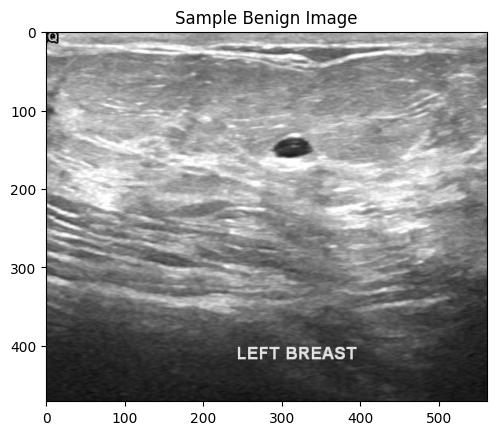

In [5]:
# Loading and Displaying an Image

import cv2
import matplotlib.pyplot as plt
import os

# Define the path to the benign images
benign_path = './Dataset_BUSI_with_GT/benign'

# Get the name of the first image file
first_image_name = os.listdir(benign_path)[0]

# Create the full path to that image
image_path = os.path.join(benign_path, first_image_name)

# Load the image using OpenCV
img = cv2.imread(image_path)

# Check the variables
print(img)

# Display the image using Matplotlib
plt.imshow(img)
plt.title('Sample Benign Image')
plt.show()

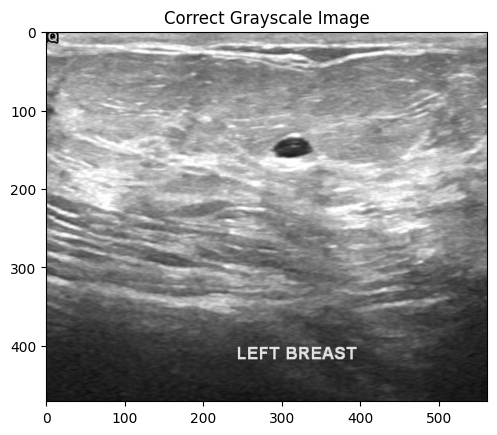

In [6]:
# Load the image in grayscale mode directly, which is more efficient
gray_img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Display the image using a gray colormap
plt.imshow(gray_img, cmap='gray')
plt.title('Correct Grayscale Image')
plt.show()

In [7]:
import cv2

# Load the image in grayscale
gray_img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Define the new dimensions
new_size = (128, 128) # width, height

# Resize the image
resized_img = cv2.resize(gray_img, new_size)

# Print the shape of the new image to confirm
print(f'The new image shape is: {resized_img.shape}')

The new image shape is: (128, 128)


In [ ]:
# Processing the Full Dataset

In [8]:
import os
import cv2
import numpy as np

dataset_path = './Dataset_BUSI_with_GT'
classes = ['benign', 'malignant', 'normal']
img_size = (128, 128)

data = []
labels = []

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)
    for img_name in os.listdir(class_path):
        try:
            img_path = os.path.join(class_path, img_name)
            img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            resized_array = cv2.resize(img_array, img_size)
            
            data.append(resized_array)
            
            if class_name == 'benign':
                labels.append(0)
            elif class_name == 'malignant':
                labels.append(1)
            else:
                labels.append(2)
        except Exception as e:
            print(f"Error processing image {img_path}: {e}")

# Convert lists to NumPy arrays
data = np.array(data)
labels = np.array(labels)

print(f"Data shape: {data.shape}")
print(f"Labels shape: {labels.shape}")

Data shape: (1578, 128, 128)
Labels shape: (1578,)


Data shape: (1578, 128, 128): This means we have 1,578 images, and each one is 128x128 pixels.

Labels shape: (1578,): This means we have 1,578 labels, one for each image.

In [ ]:
# Training a model
## Splitting the Dataset

In [9]:
from sklearn.model_selection import train_test_split

# Split the data
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=42)

# Print the shapes of the new arrays
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (1262, 128, 128)
X_test shape: (316, 128, 128)


In [ ]:
# Building the Model with Keras (CNN architecture.)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    # First Convolutional Block
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu', input_shape=(128, 128, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Second Convolutional Block
    Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Translator/Flattener
    Flatten(),
    
    # A standard Dense layer for learning
    Dense(64, activation='relu'),

    # Final Output Layer
    Dense(3, activation='softmax')
])

# Print a summary of the model
model.summary()

c:\Users\lelin\workspace\AIData_Engineer\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,705,475 (14.14 MB)

 Trainable params: 3,705,475 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# Compiling the Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

print("Model compiled successfully.")

Model compiled successfully.


In [18]:
#Train the model
history = model.fit(X_train, y_train, epochs=15, validation_data=(X_test, y_test))

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 279s 5s/step - accuracy: 0.5618 - loss: 27.2988 - val_accuracy: 0.6076 - val_loss: 0.9292
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 217s 5s/step - accuracy: 0.6204 - loss: 0.8005 - val_accuracy: 0.6013 - val_loss: 0.9117
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 200s 4s/step - accuracy: 0.6696 - loss: 0.6648 - val_accuracy: 0.5981 - val_loss: 0.9041
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 206s 5s/step - accuracy: 0.7227 - loss: 0.6284 - val_accuracy: 0.6835 - val_loss: 0.9804
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 233s 5s/step - accuracy: 0.7742 - loss: 0.5488 - val_accuracy: 0.6899 - val_loss: 1.0417
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 305s 6s/step - accuracy: 0.8368 - loss: 0.4254 - val_accuracy: 0.7057 - val_loss: 1.1208
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 195s 5s/step - accuracy: 0.8494 - loss: 0.3548 - val_accuracy: 0.7089 - val_loss: 1.1845
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 203s 5s/step - accuracy: 0.8629 - loss: 0.3206 - val_accuracy: 0.7184 - 

In [ ]:
# Training history:

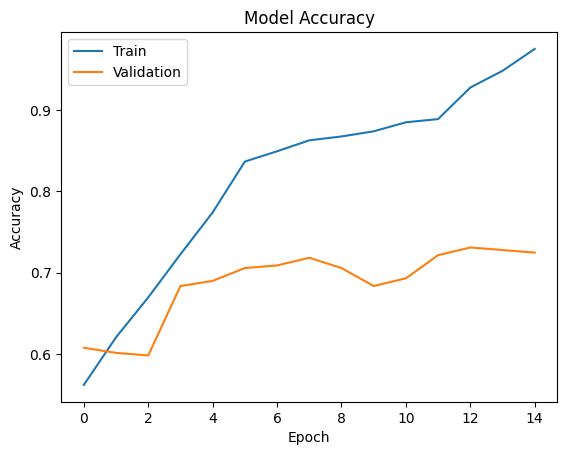

In [19]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

Overfitting
Notice how the final training accuracy is very high (97.5%), but the val_accuracy is much lower (72.5%). This large gap is a classic sign of overfitting.

In [21]:
# Improving the Model (Data Augmentation)

## BUILDING THE AUGMENTED MODEL
model_aug = Sequential([
    # First Convolutional Block
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu', input_shape=(128, 128, 1)),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Second Convolutional Block
    Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    
    # Translator/Flattener
    Flatten(),
    
    # A standard Dense layer for learning
    Dense(64, activation='relu'),

    # Final Output Layer
    Dense(3, activation='softmax')
])

# Print a summary of the model
model_aug.summary()

c:\Users\lelin\workspace\AIData_Engineer\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,705,475 (14.14 MB)

 Trainable params: 3,705,475 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:


# Compile the new model
model_aug.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

print("New model with augmentation compiled successfully!")

New model with augmentation compiled successfully!


In [23]:
# Training the Model
history_aug = model_aug.fit(X_train, y_train, epochs=15, validation_data=(X_test, y_test))

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 220s 4s/step - accuracy: 0.4842 - loss: 24.3105 - val_accuracy: 0.5981 - val_loss: 0.9025
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 184s 5s/step - accuracy: 0.6823 - loss: 0.6967 - val_accuracy: 0.5886 - val_loss: 0.8898
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 172s 4s/step - accuracy: 0.7504 - loss: 0.5031 - val_accuracy: 0.6930 - val_loss: 0.9335
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 205s 4s/step - accuracy: 0.8835 - loss: 0.3480 - val_accuracy: 0.6392 - val_loss: 1.1059
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 219s 5s/step - accuracy: 0.9255 - loss: 0.1973 - val_accuracy: 0.6994 - val_loss: 1.2010
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 187s 4s/step - accuracy: 0.9651 - loss: 0.1088 - val_accuracy: 0.6867 - val_loss: 1.6074
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 214s 5s/step - accuracy: 0.9707 - loss: 0.0844 - val_accuracy: 0.6899 - val_loss: 1.3948
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 201s 4s/step - accuracy: 0.9802 - loss: 0.0776 - val_accuracy: 0.6741 - 

In [ ]:
# Training history:

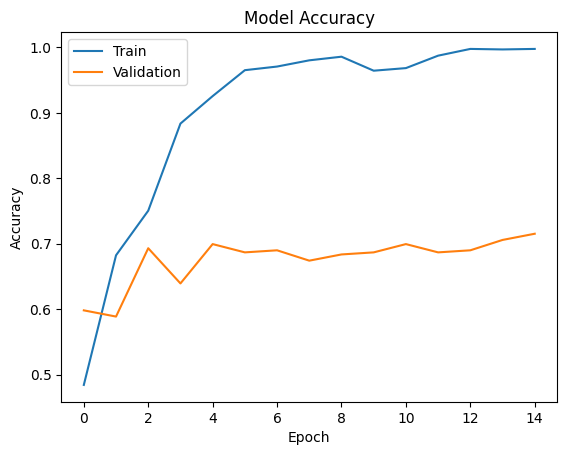

In [26]:
import matplotlib.pyplot as plt

plt.plot(history_aug.history['accuracy'])
plt.plot(history_aug.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

# Building the Dropout Model

In [ ]:
from tensorflow.keras.layers import Dropout, Input

model_drop = Sequential([
    # Convolutional blocks are the same
    Input(shape=(128, 128, 1)),
    Conv2D(filters=32, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(filters=64, kernel_size=(3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    # Flatten and add the Dense/Dropout block
    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5), # This drops out 50% of the neurons from the layer above

    # Final Output Layer
    Dense(3, activation='softmax')
])

In [29]:
model_drop.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,705,475 (14.14 MB)

 Trainable params: 3,705,475 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:
# Compiling

# Compile the new model with Dropout
model_drop.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

# Train the new model
history_drop = model_drop.fit(X_train, y_train, epochs=15, validation_data=(X_test, y_test))

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 299s 6s/step - accuracy: 0.5127 - loss: 11.9239 - val_accuracy: 0.6709 - val_loss: 0.7974
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 259s 5s/step - accuracy: 0.6957 - loss: 0.7296 - val_accuracy: 0.6962 - val_loss: 0.6896
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 260s 5s/step - accuracy: 0.7536 - loss: 0.5882 - val_accuracy: 0.6835 - val_loss: 0.6773
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 267s 6s/step - accuracy: 0.7964 - loss: 0.5252 - val_accuracy: 0.7057 - val_loss: 0.7102
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 307s 7s/step - accuracy: 0.8265 - loss: 0.4502 - val_accuracy: 0.7342 - val_loss: 0.7335
Epoch 6/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 132s 3s/step - accuracy: 0.8502 - loss: 0.3886 - val_accuracy: 0.7405 - val_loss: 0.7021
Epoch 7/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 121s 3s/step - accuracy: 0.8883 - loss: 0.2947 - val_accuracy: 0.7215 - val_loss: 0.9277
Epoch 8/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - accuracy: 0.9065 - loss: 0.2326 - val_accuracy: 0.7405 - v

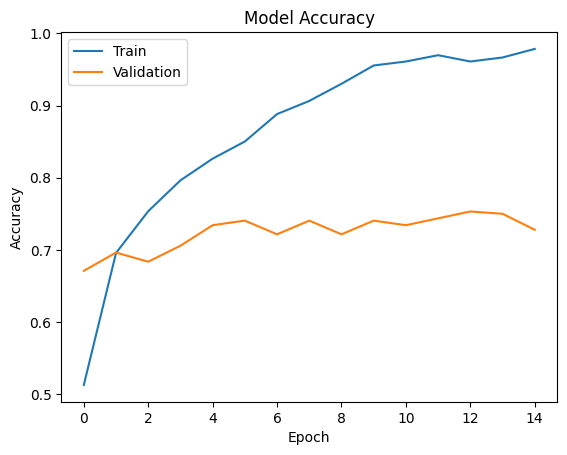

In [31]:
import matplotlib.pyplot as plt

plt.plot(history_drop.history['accuracy'])
plt.plot(history_drop.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [37]:
# Early Stopping

from tensorflow.keras.callbacks import EarlyStopping

# This will monitor the validation loss and stop if it doesn't improve for 3 epochs
early_stopping = EarlyStopping(monitor='val_loss', patience=3)

# Retrain our best model (the one with Dropout) using this new callback
history_final = model_drop.fit(X_train, y_train, 
                               epochs=15, 
                               validation_data=(X_test, y_test),
                               callbacks=[early_stopping])

Epoch 1/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 452s 9s/step - accuracy: 0.9889 - loss: 0.0450 - val_accuracy: 0.7310 - val_loss: 2.3872
Epoch 2/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 489s 12s/step - accuracy: 0.9865 - loss: 0.0300 - val_accuracy: 0.7437 - val_loss: 2.0623
Epoch 3/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 462s 11s/step - accuracy: 0.9889 - loss: 0.0347 - val_accuracy: 0.7595 - val_loss: 2.8663
Epoch 4/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 330s 8s/step - accuracy: 0.9937 - loss: 0.0306 - val_accuracy: 0.7373 - val_loss: 2.1943
Epoch 5/15
40/40 ━━━━━━━━━━━━━━━━━━━━ 231s 6s/step - accuracy: 0.9881 - loss: 0.0757 - val_accuracy: 0.7468 - val_loss: 2.6187


In [2]:
import matplotlib.pyplot as plt

plt.plot(history_final.history['accuracy'])
plt.plot(history_final.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

NameError: name 'history_final' is not defined

In [39]:
# Save the model to a file
model_drop.save('breast_cancer_model_final.keras')

print("Final model saved successfully!")

Final model saved successfully!


In [13]:
import os
import cv2

# Create the directory if it doesn't exist
if not os.path.exists('test_images'):
    os.makedirs('test_images')

# Take an image from your test set
# sample_test_image = X_test[0] 
for i in range (10):
    sample_test_image = X_test[i] 
    # Define the full path for the new image
    new_path = os.path.join('test_images', f"sample_test_image_0{i}.png")
    # # Save the image to that path
    cv2.imwrite(new_path, sample_test_image)

print(f"Saved test image to '{new_path}'")

Saved test image to 'test_images\sample_test_image_09.png'
